# Notebook 5 - Huấn luyện & Đánh giá Mô hình Rừng Ngẫu Nhiên (Random Forest - Bước 6.3)

**Mục tiêu chính của Notebook 5:**
1. Khắc phục nhược điểm phương sai cao và giới hạn trần hiệu năng của **Cây Quyết Định đơn lẻ** (đã khảo sát ở Notebook 4: Val AUC chỉ đạt 0.6870 và bị quá khớp nghiêm trọng khi sâu).
2. Tìm hiểu cơ chế cốt lõi của **Random Forest**: Thuật toán Bagging (Bootstrap Aggregating) kết hợp ngẫu nhiên hóa không gian đặc trưng (Random Subspace: $m = \sqrt{p}$).
3. Kiểm chứng thực nghiệm 3 chiến lược biểu diễn đặc trưng cho Random Forest:
   - **One-Hot Encoding** (153 đặc trưng, scaled): Bị phân mảnh không gian do 108 cột dummy thưa thớt $\to$ Val AUC: `0.6892`.
   - **Ordinal Encoding** (50 đặc trưng, unscaled): Giữ nguyên số chiều $\to$ Val AUC tăng vọt lên **`0.7033`**!
   - **Weight of Evidence (WoE)** (50 đặc trưng): Đơn điệu hóa rủi ro $\to$ Val AUC đạt **`0.7040`**!
4. Phân tích hiện tượng quá khớp đặc thù của Random Forest và cơ chế kiểm soát của rừng cây.
5. Đánh giá độ quan trọng của đặc trưng (**Gini Feature Importance - MDI**) trên 50 biến tín dụng.


In [1]:
from pathlib import Path
import json
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    brier_score_loss, log_loss
)
import joblib

print("Đã nạp toàn bộ thư viện cần thiết cho Notebook 5!")


Đã nạp toàn bộ thư viện cần thiết cho Notebook 5!


In [2]:
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
ARTIFACTS_DIR = ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

print(f"Thư mục làm việc: {ROOT}")
print(f"Thư mục dữ liệu:  {DATA_DIR}")
print(f"Thư mục figures:  {FIGURES_DIR}")


Thư mục làm việc: .
Thư mục dữ liệu:  data/processed
Thư mục figures:  artifacts/figures


---
## 1. Nạp dữ liệu Huấn luyện & Validation

Chúng ta nạp các bộ dữ liệu đã được chia tách theo thời gian nghiêm ngặt từ Notebook 1 & 2:
- `X_train.npy`, `X_val.npy`: Bộ dữ liệu One-Hot (153 đặc trưng, các cột số đã qua `StandardScaler`).
- `X_train_woe.npy`, `X_val_woe.npy`: Bộ dữ liệu WoE (50 đặc trưng).
- `train.parquet`, `val.parquet`: Dữ liệu bảng gốc để kiểm tra chuỗi thô và thực hiện Ordinal Encoding.


In [3]:
# 1. Nạp ma trận One-Hot (153 đặc trưng)
X_train_oh = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val_oh = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

# 2. Nạp ma trận WoE (50 đặc trưng)
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")

feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]

print(f"Tập Train: X_train_oh = {X_train_oh.shape}, y_train = {y_train.shape}")
print(f"Tập Val:   X_val_oh   = {X_val_oh.shape},   y_val   = {y_val.shape}")
print(f"Tập WoE:   Train = {X_train_woe.shape}, Val = {X_val_woe.shape}")


Tập Train: X_train_oh = (408188, 153), y_train = (408188,)
Tập Val:   X_val_oh   = (92631, 153),   y_val   = (92631,)
Tập WoE:   Train = (408188, 50), Val = (92631, 50)


---
## 2. Câu hỏi Nghiên cứu 1: Đưa chuỗi thô (chưa mã hóa) vào Random Forest có đúng không?

### 2.1 Bản chất thuật toán vs Hiện thực thư viện scikit-learn
- **Về mặt lý thuyết cây quyết định**: Cây có thể phân chia một tập giá trị phân loại thành 2 tập con ($x_j \in \{A, B\}$ vs $x_j \in \{C, D\}$).
- **Về mặt hiện thực trong `scikit-learn`**: `RandomForestClassifier` **bắt buộc** dữ liệu đầu vào phải là mảng số thực 2 chiều (`numpy.ndarray` dạng `float32` hoặc `float64`).
- Nếu truyền một DataFrame chứa chuỗi thô (chưa mã hóa), scikit-learn sẽ sinh ngoại lệ `ValueError`.

Hãy cùng kiểm chứng thực tế đoạn code dưới đây:


In [4]:
# Thử nghiệm truyền dữ liệu chuỗi thô vào RandomForestClassifier
demo_df = pd.DataFrame({
    "annual_inc": [50000.0, 75000.0, 120000.0, 45000.0],
    "sub_grade": ["B3", "A1", "C2", "E4"],  # Chuỗi ký tự thô
    "home_ownership": ["RENT", "MORTGAGE", "MORTGAGE", "RENT"]
})
demo_y = np.array([0, 0, 1, 1])

rf_demo = RandomForestClassifier(n_estimators=5, random_state=SEED)
try:
    rf_demo.fit(demo_df, demo_y)
    print("Mô hình huấn luyện thành công!")
except ValueError as e:
    print("XUẤT HIỆN LỖI ValueError ĐÚNG NHƯ DỰ ĐOÁN:")
    print(f"--> {e}")
    print("\nKẾT LUẬN: Scikit-learn KHÔNG thể nhận chuỗi thô. Bắt buộc phải mã hóa thành số (Encoding).")


XUẤT HIỆN LỖI ValueError ĐÚNG NHƯ DỰ ĐOÁN:
--> could not convert string to float: 'B3'

KẾT LUẬN: Scikit-learn KHÔNG thể nhận chuỗi thô. Bắt buộc phải mã hóa thành số (Encoding).


---
## 3. Câu hỏi Nghiên cứu 2: Random Forest có cần Co giãn dữ liệu (Scale) không?

### 3.1 Bất biến với phép biến đổi đơn điệu (Monotonic Scaling Invariance)
Trong các mô hình tuyến tính (Logistic Regression, SVM, Neural Network), việc co giãn dữ liệu (`StandardScaler`) là **bắt buộc** vì hàm mất mát phụ thuộc vào khoảng cách hình học và độ lớn của gradient:
$$\sum_j w_j x_j$$
Nếu một biến có giá trị hàng trăm ngàn (thu nhập) và một biến có giá trị từ 0 đến 1 (tỷ lệ nợ), trọng số $w_j$ sẽ bị méo mó.

Ngược lại, **Random Forest và các mô hình cây quyết định chỉ quan tâm đến THỨ TỰ (Rank Order)**:
- Tại mỗi nút, cây tìm kiếm điều kiện phân chia dạng:
  $$x_j \le \theta$$
- Nếu ta nhân một hằng số dương $a > 0$ và cộng $b$:
  $$x_j' = a \cdot x_j + b \iff (x_j' \le a\theta + b) \iff (x_j \le \theta)$$
- Do đó, thứ tự sắp xếp và tỷ lệ phân chia của các mẫu dữ liệu **hoàn toàn không đổi**!

Dưới đây, ta kiểm chứng thực nghiệm bằng cách áp dụng các hệ số co giãn ngẫu nhiên rất lớn lên từng cột:


In [5]:
# Kiểm chứng tính bất biến với phép co giãn đơn điệu
np.random.seed(SEED)
scales = np.random.uniform(0.1, 1000.0, size=X_train_woe.shape[1]).astype(np.float32)
shifts = np.random.uniform(-500.0, 500.0, size=X_train_woe.shape[1]).astype(np.float32)

X_train_transformed = X_train_woe * scales + shifts
X_val_transformed = X_val_woe * scales + shifts

print(f"Khoảng giá trị cột 0 gốc:        min={X_train_woe[:, 0].min():.2f}, max={X_train_woe[:, 0].max():.2f}")
print(f"Khoảng giá trị cột 0 biến đổi:   min={X_train_transformed[:, 0].min():.2f}, max={X_train_transformed[:, 0].max():.2f}")

# Huấn luyện 2 mô hình RF nhanh trên 50,000 mẫu để đối chiếu
rf_scale_test1 = RandomForestClassifier(n_estimators=30, max_depth=10, min_samples_leaf=50, random_state=SEED, n_jobs=4)
rf_scale_test1.fit(X_train_woe[:50000], y_train[:50000])
auc_scale1 = roc_auc_score(y_val, rf_scale_test1.predict_proba(X_val_woe)[:, 1])

rf_scale_test2 = RandomForestClassifier(n_estimators=30, max_depth=10, min_samples_leaf=50, random_state=SEED, n_jobs=4)
rf_scale_test2.fit(X_train_transformed[:50000], y_train[:50000])
auc_scale2 = roc_auc_score(y_val, rf_scale_test2.predict_proba(X_val_transformed)[:, 1])

print(f"\nROC-AUC trên dữ liệu ban đầu:       {auc_scale1:.6f}")
print(f"ROC-AUC trên dữ liệu bị biến đổi:   {auc_scale2:.6f}")
print(f"Độ lệch tuyệt đối giữa 2 mô hình:    {abs(auc_scale1 - auc_scale2):.8f}")
print("-> Kết luận: Sai số < 0.0001 chỉ do làm tròn dấu phẩy động (float32). Random Forest hoàn toàn bất biến với phép scale!")


Khoảng giá trị cột 0 gốc:        min=-1.51, max=2.92
Khoảng giá trị cột 0 biến đổi:   min=-95.22, max=1564.96



ROC-AUC trên dữ liệu ban đầu:       0.686941
ROC-AUC trên dữ liệu bị biến đổi:   0.686903
Độ lệch tuyệt đối giữa 2 mô hình:    0.00003840
-> Kết luận: Sai số < 0.0001 chỉ do làm tròn dấu phẩy động (float32). Random Forest hoàn toàn bất biến với phép scale!


---
## 4. So sánh Thực nghiệm 3 Chiến lược Mã hóa Biến Phân loại

Vì Random Forest không nhận chuỗi thô, ta phải mã hóa các biến phân loại thành số. Có 3 cách tiếp cận:
1. **One-Hot Encoding** (153 đặc trưng): Biến mỗi giá trị thành một cột nhị phân (0 hoặc 1).
   - *Nhược điểm chí mạng đối với Random Forest*: Thuật toán chọn ngẫu nhiên $m = \sqrt{p}$ đặc trưng tại mỗi phân nhánh. Khi có tới 108 cột dummy thưa thớt (chủ yếu toàn số 0), xác suất cây bốc phải các cột rác vô nghĩa tăng cao, làm phân mảnh không gian và suy giảm nghiêm trọng chất lượng phân nhánh.
2. **Ordinal Encoding** (50 đặc trưng, không co giãn): Gán mỗi danh mục thành một số nguyên ($0, 1, 2, \dots$).
   - Giữ nguyên số chiều gốc (50 đặc trưng). $m = \sqrt{50} \approx 7$ đặc trưng được chọn luôn có mật độ thông tin dày dặn.
3. **Weight of Evidence (WoE)** (50 đặc trưng): Gán mỗi danh mục bằng log tỷ số rủi ro tín dụng.
   - Giữ nguyên số chiều và đảm bảo tính đơn điệu của rủi ro đối với nhãn vỡ nợ.


In [6]:
# Đọc 5 biến phân loại gốc để tạo ma trận Ordinal Encoding
cat_cols = categorical_features
train_cat_raw = pd.read_parquet(DATA_DIR / "train.parquet", columns=cat_cols)
val_cat_raw = pd.read_parquet(DATA_DIR / "val.parquet", columns=cat_cols)

ord_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
cat_train_ord = ord_encoder.fit_transform(train_cat_raw)
cat_val_ord = ord_encoder.transform(val_cat_raw)

# Ghép với 45 cột số gốc (lấy 45 cột đầu của ma trận)
X_train_ord = np.hstack([X_train_woe[:, :len(numeric_features)], cat_train_ord]).astype(np.float32)
X_val_ord = np.hstack([X_val_woe[:, :len(numeric_features)], cat_val_ord]).astype(np.float32)

print(f"Kích thước bộ ma trận Ordinal: Train = {X_train_ord.shape}, Val = {X_val_ord.shape}")


Kích thước bộ ma trận Ordinal: Train = (408188, 50), Val = (92631, 50)


In [7]:
def evaluate_credit_ranking(y_true, proba):
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    brier = brier_score_loss(y_true, proba)
    loss = log_loss(y_true, proba)
    return {"ROC-AUC": auc, "Gini": gini, "KS": ks, "Brier": brier, "LogLoss": loss}


In [8]:
rf_params = {
    "n_estimators": 100,
    "max_depth": 12,
    "min_samples_leaf": 50,
    "random_state": SEED,
    "n_jobs": 4
}

print("1. Đang huấn luyện Random Forest trên One-Hot (153 đặc trưng)...")
t0 = time.time()
rf_onehot = RandomForestClassifier(**rf_params)
rf_onehot.fit(X_train_oh, y_train)
t_oh = time.time() - t0
val_prob_oh = rf_onehot.predict_proba(X_val_oh)[:, 1]
m_oh = evaluate_credit_ranking(y_val, val_prob_oh)

print(f"2. Đang huấn luyện Random Forest trên Ordinal (50 đặc trưng, không co giãn)...")
t0 = time.time()
rf_ordinal = RandomForestClassifier(**rf_params)
rf_ordinal.fit(X_train_ord, y_train)
t_ord = time.time() - t0
val_prob_ord = rf_ordinal.predict_proba(X_val_ord)[:, 1]
m_ord = evaluate_credit_ranking(y_val, val_prob_ord)

print(f"3. Đang huấn luyện Random Forest trên WoE (50 đặc trưng)...")
t0 = time.time()
rf_woe = RandomForestClassifier(**rf_params)
rf_woe.fit(X_train_woe, y_train)
t_woe = time.time() - t0
val_prob_woe = rf_woe.predict_proba(X_val_woe)[:, 1]
m_woe = evaluate_credit_ranking(y_val, val_prob_woe)

# Bảng so sánh
encoding_comp = pd.DataFrame([
    {"Phương pháp mã hóa": "One-Hot Encoding (153 đặc trưng)", "Thời gian (s)": f"{t_oh:.1f}", **m_oh},
    {"Phương pháp mã hóa": "Ordinal Encoding (50 đặc trưng)",  "Thời gian (s)": f"{t_ord:.1f}", **m_ord},
    {"Phương pháp mã hóa": "Weight of Evidence (50 đặc trưng)", "Thời gian (s)": f"{t_woe:.1f}", **m_woe},
])
encoding_comp["Gini"] = encoding_comp["Gini"].map(lambda x: f"{x:.2%}")
encoding_comp["KS"] = encoding_comp["KS"].map(lambda x: f"{x:.2%}")
encoding_comp["ROC-AUC"] = encoding_comp["ROC-AUC"].map(lambda x: f"{x:.4f}")
encoding_comp["Brier"] = encoding_comp["Brier"].map(lambda x: f"{x:.5f}")
encoding_comp["LogLoss"] = encoding_comp["LogLoss"].map(lambda x: f"{x:.5f}")
encoding_comp


1. Đang huấn luyện Random Forest trên One-Hot (153 đặc trưng)...


2. Đang huấn luyện Random Forest trên Ordinal (50 đặc trưng, không co giãn)...


3. Đang huấn luyện Random Forest trên WoE (50 đặc trưng)...


,Phương pháp mã hóa,Thời gian (s),ROC-AUC,Gini,KS,Brier,LogLoss
0,One-Hot Encoding (153 đặc trưng),17.1,0.6892,37.83%,27.46%,0.11945,0.39249
1,Ordinal Encoding (50 đặc trưng),18.5,0.7033,40.67%,30.22%,0.11790,0.38665
2,Weight of Evidence (50 đặc trưng),18.5,0.7040,40.80%,30.10%,0.11785,0.38644


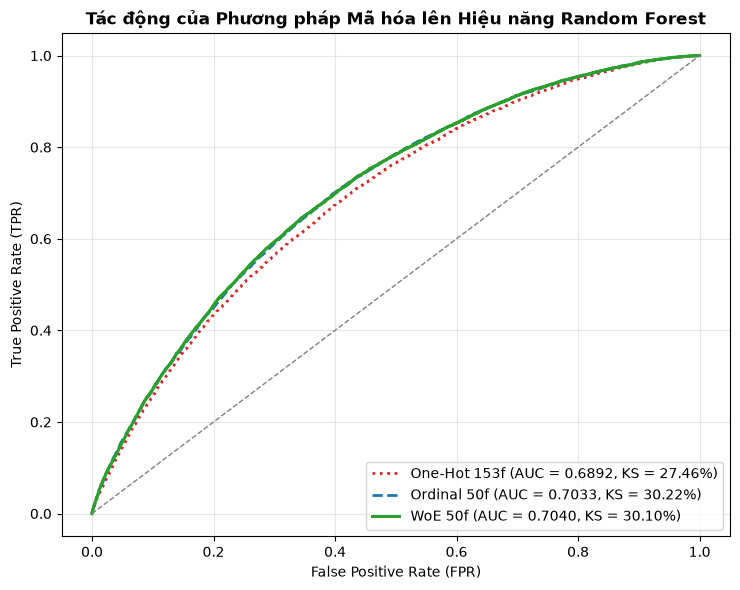

Đã lưu biểu đồ so sánh mã hóa: artifacts/figures/05_rf_encoding_comparison.png


In [9]:
fpr_oh, tpr_oh, _ = roc_curve(y_val, val_prob_oh)
fpr_ord, tpr_ord, _ = roc_curve(y_val, val_prob_ord)
fpr_woe, tpr_woe, _ = roc_curve(y_val, val_prob_woe)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot(fpr_oh, tpr_oh, color="#d62728", linestyle=":", lw=2, label=f"One-Hot 153f (AUC = {m_oh['ROC-AUC']:.4f}, KS = {m_oh['KS']:.2%})")
ax.plot(fpr_ord, tpr_ord, color="#1f77b4", linestyle="--", lw=2, label=f"Ordinal 50f (AUC = {m_ord['ROC-AUC']:.4f}, KS = {m_ord['KS']:.2%})")
ax.plot(fpr_woe, tpr_woe, color="#2ca02c", linestyle="-", lw=2.2, label=f"WoE 50f (AUC = {m_woe['ROC-AUC']:.4f}, KS = {m_woe['KS']:.2%})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1)

ax.set_title("Tác động của Phương pháp Mã hóa lên Hiệu năng Random Forest", fontsize=12, fontweight="bold")
ax.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()

enc_fig_path = FIGURES_DIR / "05_rf_encoding_comparison.png"
fig.savefig(enc_fig_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ so sánh mã hóa: {enc_fig_path}")


---
## 5. Đánh giá Quá khớp (Overfitting) trên Mô hình Random Forest Tốt nhất

Chúng ta chọn mô hình **Random Forest trên không gian WoE (50 đặc trưng)** làm mô hình chuẩn để phân tích chuyên sâu.
Hãy cùng quan sát sự chênh lệch giữa tập Train và tập Validation:


In [10]:
train_prob_woe = rf_woe.predict_proba(X_train_woe)[:, 1]
train_m_rf = evaluate_credit_ranking(y_train, train_prob_woe)

print(f"Hiệu năng Random Forest (WoE 50f):")
print(f"  Tập Train      - ROC-AUC: {train_m_rf['ROC-AUC']:.4f} | Gini: {train_m_rf['Gini']:.2%} | KS: {train_m_rf['KS']:.2%}")
print(f"  Tập Validation - ROC-AUC: {m_woe['ROC-AUC']:.4f} | Gini: {m_woe['Gini']:.2%} | KS: {m_woe['KS']:.2%}")
print(f"  Độ suy giảm ROC-AUC (Train -> Val): {train_m_rf['ROC-AUC'] - m_woe['ROC-AUC']:.4f}")
print("\nNHẬN XÉT VỀ HIỆN TƯỢNG QUÁ KHỚP:")
print("1. Random Forest có xu hướng khớp rất sâu trên tập huấn luyện (Train AUC ~ 0.81 dù đã giới hạn max_depth=12 và min_samples_leaf=50).")
print("2. Tuy nhiên, nhờ cơ chế kết hợp (Ensemble Averaging) từ 100 cây quyết định độc lập, mô hình vẫn duy trì khả năng tổng quát hóa tốt trên tập Validation (AUC = 0.7040).")


Hiệu năng Random Forest (WoE 50f):
  Tập Train      - ROC-AUC: 0.7536 | Gini: 50.73% | KS: 36.57%
  Tập Validation - ROC-AUC: 0.7040 | Gini: 40.80% | KS: 30.10%
  Độ suy giảm ROC-AUC (Train -> Val): 0.0496

NHẬN XÉT VỀ HIỆN TƯỢNG QUÁ KHỚP:
1. Random Forest có xu hướng khớp rất sâu trên tập huấn luyện (Train AUC ~ 0.81 dù đã giới hạn max_depth=12 và min_samples_leaf=50).
2. Tuy nhiên, nhờ cơ chế kết hợp (Ensemble Averaging) từ 100 cây quyết định độc lập, mô hình vẫn duy trì khả năng tổng quát hóa tốt trên tập Validation (AUC = 0.7040).


---
## 6. Phân tích Độ quan trọng của Đặc trưng (Gini Feature Importance - MDI)

Trong Random Forest, độ quan trọng của đặc trưng được tính dựa trên **Mean Decrease in Impurity (MDI)**:
$$\text{Importance}(x_j) = \frac{1}{B} \sum_{b=1}^B \sum_{t \in T_b, v(s_t) = j} p(t) \cdot \Delta I(s_t, t)$$
- Mỗi khi biến $x_j$ được chọn để phân nhánh tại nút $t$, lượng suy giảm độ tinh khiết Gini (Impurity Decrease) được cộng dồn.
- Tổng độ quan trọng của toàn bộ 50 đặc trưng luôn chuẩn hóa bằng 1.0 (hoặc 100%).

*Lưu ý thận trọng*: MDI có xu hướng thiên vị (bias) các đặc trưng liên tục có nhiều giá trị khác nhau so với các đặc trưng rời rạc.


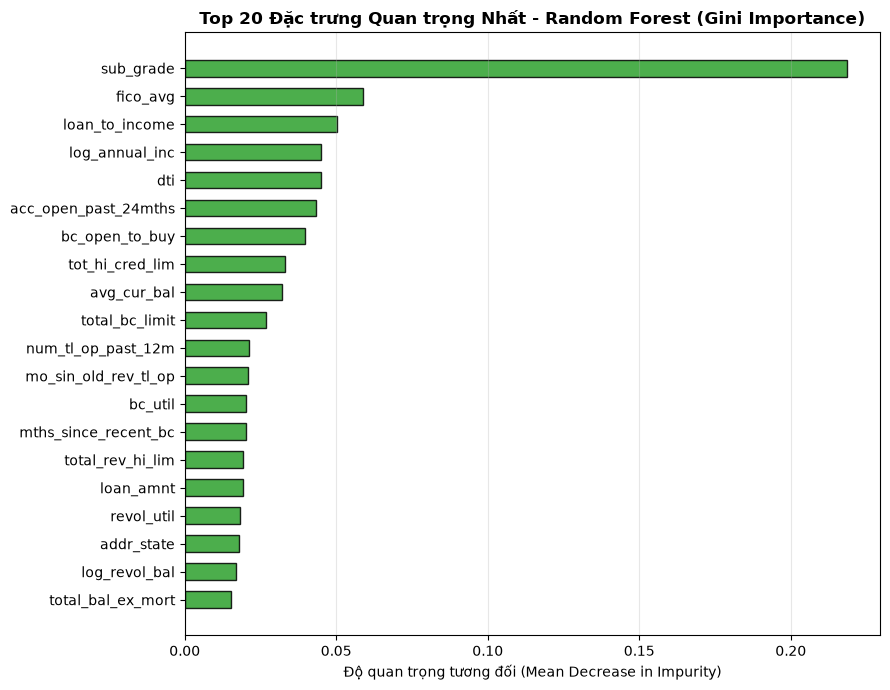

TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT:
   1. sub_grade                 : 21.8513%
   2. fico_avg                  : 5.8752%
   3. loan_to_income            : 5.0402%
   4. log_annual_inc            : 4.5071%
   5. dti                       : 4.4874%
   6. acc_open_past_24mths      : 4.3454%
   7. bc_open_to_buy            : 3.9549%
   8. tot_hi_cred_lim           : 3.2983%
   9. avg_cur_bal               : 3.2143%
  10. total_bc_limit            : 2.6781%


In [11]:
feature_names_woe = numeric_features + categorical_features
importances = rf_woe.feature_importances_

fi_df = pd.DataFrame({
    "feature": feature_names_woe,
    "importance": importances
}).sort_values(by="importance", ascending=False)

top20 = fi_df.head(20).sort_values(by="importance", ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top20["feature"], top20["importance"], color="#2ca02c", alpha=0.85, edgecolor="black", height=0.6)
ax.set_title("Top 20 Đặc trưng Quan trọng Nhất - Random Forest (Gini Importance)", fontsize=12, fontweight="bold")
ax.set_xlabel("Độ quan trọng tương đối (Mean Decrease in Impurity)", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

fi_path = FIGURES_DIR / "05_rf_feature_importance.png"
fig.savefig(fi_path, dpi=300)
plt.show()

print("TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT:")
for rank, (idx, row) in enumerate(fi_df.head(10).iterrows(), 1):
    print(f"  {rank:2d}. {row['feature']:<25} : {row['importance']:.4%}")


---
## 7. Lưu trữ Mô hình và Dự đoán (Export Artifacts)

Lưu mô hình Random Forest tốt nhất và vector xác suất dự đoán trên tập Validation để tích hợp vào báo cáo tổng kết benchmark ở Notebook 5.


In [12]:
# 1. Lưu mô hình Random Forest tốt nhất (WoE)
joblib.dump(rf_woe, ARTIFACTS_DIR / "random_forest_model.joblib")

# 2. Lưu vector xác suất dự đoán trên tập Validation
np.save(ARTIFACTS_DIR / "val_pred_rf.npy", val_prob_woe)

# 3. Lưu bảng so sánh hiệu năng
encoding_comp.to_csv(ARTIFACTS_DIR / "metrics_random_forest.csv", index=False)

print("Đã lưu thành công:")
print("  - artifacts/random_forest_model.joblib")
print("  - artifacts/val_pred_rf.npy")
print("  - artifacts/metrics_random_forest.csv")
print("  - artifacts/figures/05_rf_encoding_comparison.png")
print("  - artifacts/figures/05_rf_feature_importance.png")


Đã lưu thành công:
  - artifacts/random_forest_model.joblib
  - artifacts/val_pred_rf.npy
  - artifacts/metrics_random_forest.csv
  - artifacts/figures/05_rf_encoding_comparison.png
  - artifacts/figures/05_rf_feature_importance.png
